# Augmentation de données -- classes sous-représentées

Notebook **autonome**, séparé de `hierarchy_pytorch.ipynb` -- construit une version augmentée du
dataset fusionné, pour les classes en dessous d'un seuil de représentation, via flips et zooms.

**Point critique traité ici** : si les copies augmentées étaient mélangées aux originales avant
le split train/val/test de `hierarchy_pytorch.ipynb`, une variante augmentée d'une image de
test pourrait atterrir dans le train -- fuite de données, qui fausserait toute comparaison.
Pour l'éviter :
1. Ce notebook réplique **exactement** le même split stratifié (même graine aléatoire, mêmes
   proportions) que `hierarchy_pytorch.ipynb`
2. **Seules les images déjà assignées au train** sont augmentées -- jamais val/test
3. Un **manifeste** (`manifest.csv`) enregistre l'assignation split de chaque image (originale
   ET augmentée) -- à utiliser tel quel en aval, pas un nouveau split à refaire.

**Étape suivante, hors de ce notebook** : `hierarchy_pytorch.ipynb` devra être adapté pour lire
ce manifeste plutôt que de refaire son propre split interne -- sans quoi le risque de fuite
réapparaît. Je m'arrête volontairement à la construction du dataset ici, comme demandé.

## 1. Configuration

In [1]:
from pathlib import Path
import shutil
import numpy as np
import pandas as pd
import cv2
from sklearn.model_selection import train_test_split

DATASET_DIR_RAW = Path("/kaggle/input/datasets/jfonlupt/dataset-fusion/dataset_fusionne_filtre")

def resolve_dataset_dir(root):
    current = root
    while current.exists():
        subdirs = [d for d in current.iterdir() if d.is_dir()]
        if len(subdirs) == 1:
            current = subdirs[0]
        else:
            break
    return current

DATASET_DIR = resolve_dataset_dir(DATASET_DIR_RAW)
print("DATASET_DIR (résolu) :", DATASET_DIR, "| existe ?", DATASET_DIR.exists())

OUTPUT_DATASET_DIR = Path("/kaggle/working/dataset_augmente")
OUTPUT_DATASET_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42   # IDENTIQUE à hierarchy_pytorch.ipynb -- condition nécessaire pour
                    # reproduire exactement le même split train/val/test

# Seuil par défaut : toute classe avec moins de 1500 images en TRAIN est augmentée
MIN_TRAIN_IMAGES = 1500

# Paramètres des transformations (valeurs par défaut proposées)
ZOOM_RANGE = (0.85, 1.15)     # zoom arrière / avant, modéré -- garde le noyau dans le cadre
FLIP_PROBABILITY = 0.5        # 50% de chance chacun -- garde aussi des exemples non modifiés
ZOOM_PROBABILITY = 0.5
# MODIFIÉ : multiplicateur proportionnel à la rareté (plafonné), plutôt qu'un nombre fixe
# de variantes pour toutes les classes concernées. Motivation : avec un facteur fixe (2 avant
# ce changement), une classe extrême comme Monoblast (21 images) restait microscopique
# (21->63) alors qu'une classe déjà proche du seuil comme Metamyelocyte (1001) le dépassait
# largement (1001->3003) -- le même effort profitait très inégalement selon la classe.
# multiplicateur = seuil / nombre_actuel, plafonné pour éviter un sur-apprentissage sur
# un tout petit nombre d'images sources (ex. Monoblast à x70 théorique -- risque de
# mémorisation plutôt que de généralisation).
MAX_AUGMENTATION_MULTIPLIER = 30

# Mapping identique à hierarchy_pytorch.ipynb -- nécessaire pour charger le dataset pareil
FOLDER_TO_TARGET = {
    "Neutrophil (segmented)": "Neutrophil (segmented)",
    "Lymphocyte (typical)": "Lymphocyte",
    "Lymphocyte (atypical)": "Lymphocyte",
    "Eosinophil": "Eosinophil",
    "Myeloblast": "Myeloblast",
    "Monocyte": "Monocyte",
    "Platelet": "Platelet",
    "Neutrophil (band)": "Neutrophil (band)",
    "Erythroblast": "Erythroblast",
    "Basophil": "Basophil",
    "Myelocyte": "Myelocyte",
    "Metamyelocyte": "Metamyelocyte",
    "Promyelocyte": "Promyelocyte",
    "Promyelocyte (bilobed)": "Promyelocyte",
    "Monoblast": "Monoblast",
    "Immature Granulocyte": "Granulocytes immatures de PBC",
}

np.random.seed(RANDOM_SEED)
print(f"Seuil : classes avec moins de {MIN_TRAIN_IMAGES} images en train seront augmentées.")


DATASET_DIR (résolu) : /kaggle/input/datasets/jfonlupt/dataset-fusion/dataset_fusionne_filtre | existe ? True
Seuil : classes avec moins de 1500 images en train seront augmentées.


## 2. Chargement du dataset et split -- identique à `hierarchy_pytorch.ipynb`

Même graine, mêmes proportions (70/15/15), même colonne de stratification -- garantit que les
images qui atterrissent en train ici sont **exactement** celles qui atterriraient en train dans
le notebook d'entraînement, à condition qu'il lise ce même dossier source non modifié.

In [2]:
def load_fused_dataset():
    if not DATASET_DIR.exists():
        raise FileNotFoundError(f"DATASET_DIR introuvable : {DATASET_DIR}")
    rows = []
    for class_dir in sorted(DATASET_DIR.iterdir()):
        if not class_dir.is_dir():
            continue
        target_label = FOLDER_TO_TARGET.get(class_dir.name)
        if target_label is None:
            continue
        for f in class_dir.iterdir():
            if f.suffix.lower() in (".png", ".jpg", ".jpeg", ".tif", ".tiff"):
                rows.append({"path": f, "class_name": class_dir.name, "target_label": target_label})
    if not rows:
        raise ValueError(f"Aucune image trouvée dans {DATASET_DIR}")
    return pd.DataFrame(rows)


data = load_fused_dataset()
print(f"Total images exploitables : {len(data)}")

train_df, temp_df = train_test_split(data, test_size=0.30, stratify=data["target_label"], random_state=RANDOM_SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["target_label"], random_state=RANDOM_SEED)
print(f"Train : {len(train_df)} | Val : {len(val_df)} | Test : {len(test_df)}")

train_counts = train_df["target_label"].value_counts()
print("\nImages en train, par classe :")
print(train_counts.to_string())

classes_to_augment = sorted(train_counts[train_counts < MIN_TRAIN_IMAGES].index.tolist())
print(f"\n{len(classes_to_augment)} classes sous le seuil ({MIN_TRAIN_IMAGES}) -- seront augmentées :")

# CORRIGÉ : la version précédente calculait un multiplicateur pensé comme "total final visé
# / original", mais générait ce nombre de copies EN PLUS de l'original -- donnant
# original*(1+multiplicateur) au lieu de original*multiplicateur (un facteur de trop, day
# vérifié sur un vrai run : Platelet 1448->4344 au lieu de ~1500 attendu). Corrigé ici en
# visant directement le TOTAL exact, plafonné à (1 + MAX_AUGMENTATION_MULTIPLIER) fois
# l'original pour les classes les plus extrêmes (ex. Monoblast).
n_augmented_needed = {}
for c in classes_to_augment:
    original_count = int(train_counts[c])
    target_total = min(MIN_TRAIN_IMAGES, original_count * (1 + MAX_AUGMENTATION_MULTIPLIER))
    n_augmented_needed[c] = max(0, target_total - original_count)

print(f"\nImages augmentées prévues par classe (plafond={MAX_AUGMENTATION_MULTIPLIER}x) :")
for c in classes_to_augment:
    original_count = int(train_counts[c])
    total = original_count + n_augmented_needed[c]
    capped = " (plafonné)" if total < MIN_TRAIN_IMAGES else ""
    print(f"  {c:35s} : {original_count:5d} originales + {n_augmented_needed[c]:5d} augmentées "
          f"= {total:5d} au total{capped}")


Total images exploitables : 33577
Train : 23503 | Val : 5037 | Test : 5037

Images en train, par classe :
target_label
Neutrophil (segmented)           6735
Lymphocyte                       3392
Eosinophil                       2411
Monocyte                         2182
Myeloblast                       2161
Platelet                         1448
Neutrophil (band)                1196
Erythroblast                     1016
Basophil                          890
Myelocyte                         798
Metamyelocyte                     701
Promyelocyte                      453
Granulocytes immatures de PBC     105
Monoblast                          15

9 classes sous le seuil (1500) -- seront augmentées :

Images augmentées prévues par classe (plafond=30x) :
  Basophil                            :   890 originales +   610 augmentées =  1500 au total
  Erythroblast                        :  1016 originales +   484 augmentées =  1500 au total
  Granulocytes immatures de PBC       :   105 original

## 3. Transformations (flips + zoom)

Flips horizontal/vertical -- biologiquement valides ici (une cellule sur un frottis n'a pas
d'orientation canonique). Zoom modéré (0.85x-1.15x) -- assez large pour la diversité, assez
contenu pour garder le noyau dans le cadre.

In [3]:
def apply_zoom(img, zoom_factor):
    h, w = img.shape[:2]
    if zoom_factor >= 1.0:
        new_h, new_w = int(h / zoom_factor), int(w / zoom_factor)
        y0, x0 = (h - new_h) // 2, (w - new_w) // 2
        cropped = img[y0:y0 + new_h, x0:x0 + new_w]
        return cv2.resize(cropped, (w, h), interpolation=cv2.INTER_AREA)
    else:
        new_h, new_w = int(h * zoom_factor), int(w * zoom_factor)
        small = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)
        pad_h, pad_w = (h - new_h) // 2, (w - new_w) // 2
        return cv2.copyMakeBorder(small, pad_h, h - new_h - pad_h, pad_w, w - new_w - pad_w,
                                    cv2.BORDER_REFLECT)


def augment_image(img, rng):
    """Une variante augmentée : flip (50%) puis zoom (50%), indépendamment l'un de l'autre --
    peut donc produire flip seul, zoom seul, les deux, ou ni l'un ni l'autre (image quasi
    inchangée, cas rare mais accepté -- garde une diversité naturelle)."""
    out = img.copy()
    if rng.random() < FLIP_PROBABILITY:
        flip_code = rng.choice([0, 1])   # 0 = vertical, 1 = horizontal
        out = cv2.flip(out, flip_code)
    if rng.random() < ZOOM_PROBABILITY:
        zoom_factor = rng.uniform(*ZOOM_RANGE)
        out = apply_zoom(out, zoom_factor)
    return out


## 4. Construction du dataset de sortie + manifeste

Copie toutes les images (train/val/test, originales, inchangées) vers `OUTPUT_DATASET_DIR`, puis
ajoute les variantes augmentées **uniquement** pour les classes sous le seuil, **uniquement** à
partir d'images déjà en train. `manifest.csv` enregistre le split de chaque image -- fichier à
utiliser tel quel en aval, condition nécessaire pour ne jamais avoir à refaire le split.

In [4]:
manifest_rows = []
rng = np.random.default_rng(RANDOM_SEED)

def copy_original(row, split):
    class_dir = OUTPUT_DATASET_DIR / row["class_name"]
    class_dir.mkdir(parents=True, exist_ok=True)
    dest = class_dir / row["path"].name
    if not dest.exists():
        shutil.copy2(row["path"], dest)
    manifest_rows.append({"path": str(dest), "class_name": row["class_name"],
                            "target_label": row["target_label"], "split": split, "is_augmented": False})

print("Copie des images originales (train/val/test, inchangées)...")
for _, row in train_df.iterrows():
    copy_original(row, "train")
for _, row in val_df.iterrows():
    copy_original(row, "val")
for _, row in test_df.iterrows():
    copy_original(row, "test")
print(f"  {len(manifest_rows)} images originales copiées.")

print("\nGénération des variantes augmentées (train uniquement, classes sous le seuil)...")
n_augmented = 0
for target_label in classes_to_augment:
    class_train_df = train_df[train_df["target_label"] == target_label].reset_index(drop=True)
    n_needed = n_augmented_needed[target_label]
    n_images = len(class_train_df)

    # CORRIGÉ : distribue n_needed copies EXACTEMENT (round-robin sur les images de la
    # classe) plutôt qu'un nombre fixe par image -- garantit le total visé précisément,
    # au lieu du facteur "un de trop" de la version précédente.
    base_per_image, remainder = divmod(n_needed, n_images)
    img_cache = {}   # évite de relire le fichier depuis le disque a chaque copie
    for img_idx in range(n_images):
        row = class_train_df.iloc[img_idx]
        n_copies_this_image = base_per_image + (1 if img_idx < remainder else 0)
        if n_copies_this_image == 0:
            continue
        if img_idx not in img_cache:
            img_cache[img_idx] = cv2.imread(str(row["path"]), cv2.IMREAD_COLOR)
        img = img_cache[img_idx]
        if img is None:
            continue
        class_dir = OUTPUT_DATASET_DIR / row["class_name"]
        stem = row["path"].stem
        for k in range(n_copies_this_image):
            aug_img = augment_image(img, rng)
            aug_name = f"{stem}_aug{k+1}{row['path'].suffix}"
            dest = class_dir / aug_name
            cv2.imwrite(str(dest), aug_img)
            manifest_rows.append({"path": str(dest), "class_name": row["class_name"],
                                    "target_label": target_label, "split": "train", "is_augmented": True})
            n_augmented += 1
print(f"  {n_augmented} images augmentées générées.")

manifest_df = pd.DataFrame(manifest_rows)
manifest_path = OUTPUT_DATASET_DIR / "manifest.csv"
manifest_df.to_csv(manifest_path, index=False)
print(f"\nManifeste sauvegardé : {manifest_path} ({len(manifest_df)} lignes au total)")


Copie des images originales (train/val/test, inchangées)...
  33577 images originales copiées.

Génération des variantes augmentées (train uniquement, classes sous le seuil)...
  5843 images augmentées générées.

Manifeste sauvegardé : /kaggle/working/dataset_augmente/manifest.csv (39420 lignes au total)


## 5. Résumé -- avant / après augmentation

In [5]:
summary = manifest_df[manifest_df["split"] == "train"].groupby("target_label").agg(
    total_train=("path", "count"),
    dont_augmentees=("is_augmented", "sum"),
).sort_values("total_train")
summary["dont_originales"] = summary["total_train"] - summary["dont_augmentees"]
print(summary[["dont_originales", "dont_augmentees", "total_train"]].to_string())

print(f"\nTotal train (dataset augmenté) : {len(manifest_df[manifest_df.split=='train'])} images")
print(f"Total val   (inchangé)         : {len(manifest_df[manifest_df.split=='val'])} images")
print(f"Total test  (inchangé)         : {len(manifest_df[manifest_df.split=='test'])} images")


                               dont_originales  dont_augmentees  total_train
target_label                                                                
Monoblast                                   15              450          465
Basophil                                   890              610         1500
Granulocytes immatures de PBC              105             1395         1500
Erythroblast                              1016              484         1500
Metamyelocyte                              701              799         1500
Promyelocyte                               453             1047         1500
Neutrophil (band)                         1196              304         1500
Myelocyte                                  798              702         1500
Platelet                                  1448               52         1500
Myeloblast                                2161                0         2161
Monocyte                                  2182                0         2182

## 5bis. Métriques -- déséquilibre des classes, avant/après

Au-delà du tableau brut : un indicateur quantitatif de l'effet réel de l'augmentation sur
l'équilibre du dataset (ratio classe la plus grande / classe la plus petite), et une figure
comparant chaque classe avant/après.

Ratio de déséquilibre (classe la plus grande / la plus petite) :
  Avant augmentation : x449.0 (Neutrophil (segmented)=6735 vs Monoblast=15)
  Après augmentation  : x14.5 (Neutrophil (segmented)=6735 vs Monoblast=465)


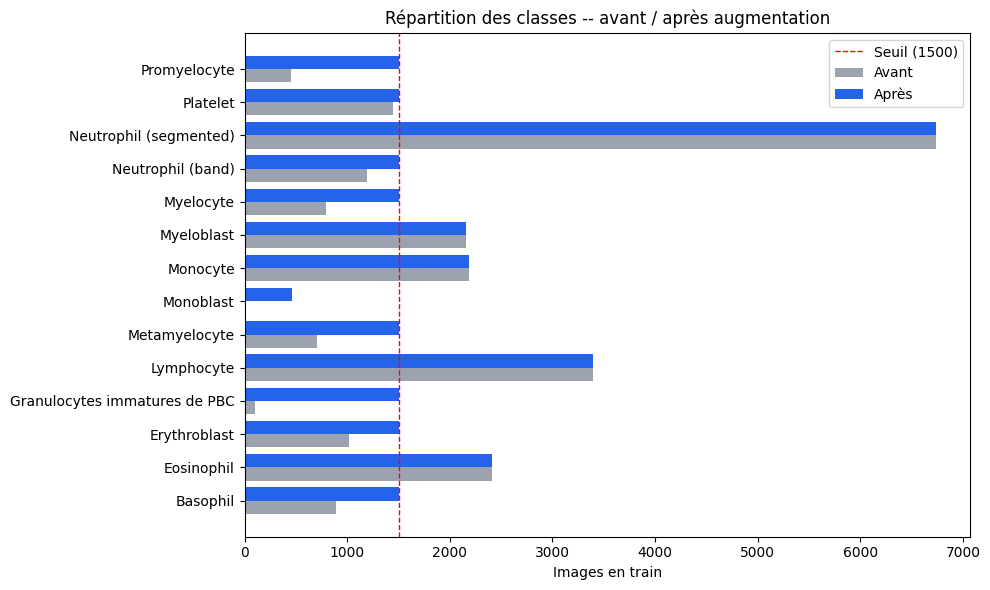

In [6]:
import matplotlib.pyplot as plt

before_counts = train_counts.sort_index()
after_counts = summary["total_train"].reindex(before_counts.index)

imbalance_before = before_counts.max() / before_counts.min()
imbalance_after = after_counts.max() / after_counts.min()
print(f"Ratio de déséquilibre (classe la plus grande / la plus petite) :")
print(f"  Avant augmentation : x{imbalance_before:.1f} "
      f"({before_counts.idxmax()}={before_counts.max()} vs {before_counts.idxmin()}={before_counts.min()})")
print(f"  Après augmentation  : x{imbalance_after:.1f} "
      f"({after_counts.idxmax()}={after_counts.max():.0f} vs {after_counts.idxmin()}={after_counts.min():.0f})")

fig, ax = plt.subplots(figsize=(10, 6))
y_pos = np.arange(len(before_counts))
ax.barh(y_pos - 0.2, before_counts.values, height=0.4, label="Avant", color="#9CA3AF")
ax.barh(y_pos + 0.2, after_counts.values, height=0.4, label="Après", color="#2563EB")
ax.set_yticks(y_pos)
ax.set_yticklabels(before_counts.index)
ax.axvline(MIN_TRAIN_IMAGES, color="red", ls="--", lw=1, label=f"Seuil ({MIN_TRAIN_IMAGES})")
ax.set_xlabel("Images en train")
ax.set_title("Répartition des classes -- avant / après augmentation")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DATASET_DIR / "metrics_avant_apres.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Étape suivante, à faire dans `hierarchy_pytorch.ipynb` (pas ici)

Pour utiliser ce dataset sans risque de fuite, remplacer le split interne actuel par une lecture
directe du manifeste :

```python
manifest_df = pd.read_csv(OUTPUT_DATASET_DIR / "manifest.csv")
train_df = manifest_df[manifest_df["split"] == "train"].copy()
val_df = manifest_df[manifest_df["split"] == "val"].copy()
test_df = manifest_df[manifest_df["split"] == "test"].copy()
```

**Ne surtout pas** relancer `train_test_split(...)` sur ce dataset augmenté -- les copies
augmentées seraient re-mélangées avec les originales et pourraient atterrir en val/test, recréant
exactement la fuite qu'on vient d'éviter ici. Je n'ai pas implémenté ce changement dans
`hierarchy_pytorch.ipynb` -- seulement préparé le dataset, comme demandé.